# BIOT 6900 · Module 6 — Toy Model: Build a Polygenic Risk Score

**In this notebook you will:** make a small synthetic cohort, build a PRS by hand with the one equation (risk alleles × weight, summed), watch cases and controls pull apart, measure how well the score separates them with the AUC, and then remove the single biggest-effect variant to see how much the score leaned on it.

> ⚠️ **All data here is SYNTHETIC** — generated by code so the machinery is fully visible. No real patients. The graded assignment uses real 1000 Genomes data.

Run top to bottom: **Kernel → Restart & Run All**.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Northeastern palette, so figures match the slides
NU_RED, NU_COOL, NU_GREY, NU_LG = "#C8102E", "#1E2028", "#6E7178", "#B8BCC2"

rng = np.random.default_rng(6900)          # fixed seed: everyone sees the same numbers
def sigmoid(x): return 1 / (1 + np.exp(-x))

## 1. Build a synthetic cohort

We invent `N` people and `M` common variants.

- **Genotypes `G`:** each entry is 0, 1, or 2 — the number of risk alleles a person carries at that variant (the *dosage*), drawn from each variant's allele frequency.
- **True effect sizes `true_beta`:** the real **per-allele log-odds**. Most are tiny; **one is large** (our stand-in for *APOE* in Alzheimer's, odds ratio e^0.8 ≈ 2.2 per allele).
- **Disease status (logistic model):** each person's disease *probability* follows `logit(p) = intercept + (genotypes · true effects)`; we set the intercept for ~30% prevalence, then flip a weighted coin per person. Because the effects are on the log-odds scale, calling them log-odds is exactly right.


In [2]:
N, M = 4000, 20                               # 4000 people, 20 variants
maf = rng.uniform(0.1, 0.5, M)                # minor allele frequency per variant
G = rng.binomial(2, maf, size=(N, M))         # genotype dosages: N people x M variants

true_beta = rng.normal(0, 0.08, M)            # per-allele log-odds; most effects tiny
true_beta[0] = 0.8                            # ONE large effect (APOE-like): OR = e^0.8 ≈ 2.2

snp_names = [f"SNP{i:02d}" for i in range(M)]
snp_names[0] = "APOE_like"

# Logistic model: disease probability rises with the genetic score
score      = G @ true_beta
intercept  = np.log(0.30 / 0.70) - score.mean()      # aim for ~30% prevalence
p_disease  = sigmoid(intercept + score)
disease    = (rng.uniform(size=N) < p_disease).astype(int)

print(f"Synthetic cohort: {N} people, {M} variants, {disease.mean()*100:.0f}% cases")

Synthetic cohort: 4000 people, 20 variants, 33% cases


## 2. Look at the pieces

First the genotype matrix: one row per person, one column per variant, values 0/1/2.

In [3]:
geno_df = pd.DataFrame(G, columns=snp_names)
geno_df.insert(0, "disease", disease)
geno_df.head()

,disease,APOE_like,SNP01,SNP02,SNP03,SNP04,SNP05,SNP06,SNP07,SNP08,...,SNP10,SNP11,SNP12,SNP13,SNP14,SNP15,SNP16,SNP17,SNP18,SNP19
0,0,0,1,0,1,1,1,0,1,0,...,0,0,0,1,1,0,0,0,0,0
1,1,0,1,0,2,0,2,1,1,1,...,1,0,0,0,1,1,2,0,0,0
2,0,0,2,1,0,0,1,0,1,0,...,0,1,1,0,1,0,0,0,0,0
3,0,0,1,0,1,0,1,0,0,1,...,2,1,1,0,0,1,1,0,0,0
4,1,1,1,0,0,0,2,0,1,0,...,2,0,0,0,2,1,2,0,0,2


Now the **weights you would download** from the PGS Catalog. In the real world these come from a GWAS, so they are *estimates* of the true log-odds, not the truth. We mimic that by adding a little noise to `true_beta`.

In [4]:
weights = true_beta + rng.normal(0, 0.02, M)      # GWAS-estimated log-odds (what you'd download)

weights_table = pd.DataFrame({
    "variant": snp_names,
    "risk_allele_freq": maf.round(2),
    "weight_logodds": weights.round(3),
})
weights_table

,variant,risk_allele_freq,weight_logodds
0,APOE_like,0.45,0.784
1,SNP01,0.45,0.035
2,SNP02,0.28,-0.019
3,SNP03,0.29,-0.065
4,SNP04,0.11,0.108
5,SNP05,0.48,-0.109
6,SNP06,0.29,0.029
7,SNP07,0.28,-0.086
8,SNP08,0.38,0.071
9,SNP09,0.50,-0.041


## 3. The PRS equation, in code

The whole idea is one line. For each person,

$$\text{PRS} = \sum_{\text{variants}} (\text{risk alleles carried}) \times (\text{weight}).$$

That sum over variants, for every person at once, is just the matrix product `G @ weights`.

In [5]:
prs   = G @ weights                        # one number per person
prs_z = (prs - prs.mean()) / prs.std()     # standardize: 0 = average, units = SD

print("First five people's PRS (standardized):", prs_z[:5].round(2))

First five people's PRS (standardized): [-0.99 -1.65 -1.21 -1.35 -0.28]


## 4. Do cases score higher?

Plot the score for controls and cases. Expect the cases shifted toward higher scores, but with heavy overlap — a PRS is *risk*, not a diagnosis.

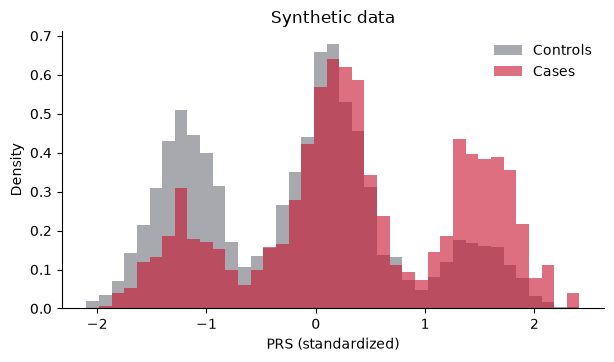

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(prs_z.min(), prs_z.max(), 40)
ax.hist(prs_z[disease == 0], bins=bins, density=True, color=NU_GREY, alpha=0.6, label="Controls")
ax.hist(prs_z[disease == 1], bins=bins, density=True, color=NU_RED,  alpha=0.6, label="Cases")
ax.set_xlabel("PRS (standardized)"); ax.set_ylabel("Density")
ax.set_title("Synthetic data"); ax.legend(frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

## 5. How well does it separate? AUC and ROC

**AUC** is the chance that a randomly chosen case has a higher PRS than a randomly chosen control. 0.5 is a coin flip; 1.0 is perfect. Common-disease PRS usually land in the **0.6s** — don't expect more.

AUC = 0.659


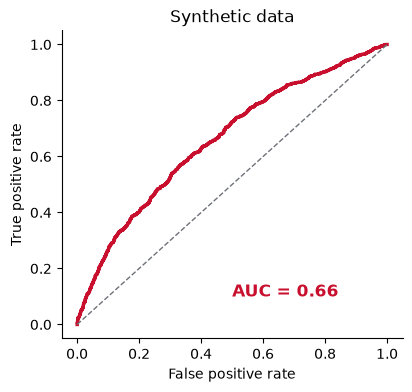

In [7]:
auc = roc_auc_score(disease, prs_z)
print(f"AUC = {auc:.3f}")

fpr, tpr, _ = roc_curve(disease, prs_z)
fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.plot(fpr, tpr, color=NU_RED, lw=2.4)
ax.plot([0, 1], [0, 1], color=NU_GREY, ls="--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Synthetic data")
ax.text(0.5, 0.1, f"AUC = {auc:.2f}", color=NU_RED, fontsize=12, fontweight="bold")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

## 6. Remove the biggest-effect variant (APOE-like)

How much of the score was just that one variant? Drop it and recompute the AUC. This is the habit from the lecture: always check whether one large-effect locus is carrying your "polygenic" score.

AUC with    APOE-like: 0.659
AUC without APOE-like: 0.536


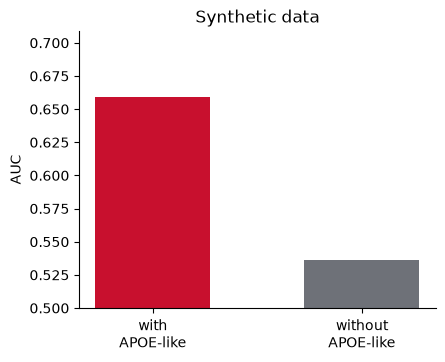

In [8]:
prs_noAPOE = G[:, 1:] @ weights[1:]          # everything except column 0 (APOE_like)
auc_noAPOE = roc_auc_score(disease, prs_noAPOE)

print(f"AUC with    APOE-like: {auc:.3f}")
print(f"AUC without APOE-like: {auc_noAPOE:.3f}")

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.bar(["with\nAPOE-like", "without\nAPOE-like"], [auc, auc_noAPOE],
       color=[NU_RED, NU_GREY], width=0.55)
ax.set_ylim(0.5, max(auc, auc_noAPOE) + 0.05); ax.set_ylabel("AUC")
ax.set_title("Synthetic data")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

## Your turn

Small experiments — change a value, re-run the cell, and watch the AUC. Use this helper:

In [9]:
def prs_auc(betas):
    """Score everyone with the given weights and return the AUC."""
    return roc_auc_score(disease, G @ betas)

# 1) Halve the APOE-like effect. How far does the AUC fall?
# w = weights.copy(); w[0] = w[0] / 2
# print(round(prs_auc(w), 3))

# 2) Zero it out entirely (same as Section 6):
# w = weights.copy(); w[0] = 0
# print(round(prs_auc(w), 3))

# 3) Make the GWAS 'noisier' (worse weights) and watch the AUC drop:
# noisy = true_beta + rng.normal(0, 0.15, M)
# print(round(prs_auc(noisy), 3))

## What you saw

- A PRS is just **dosages × weights, summed** — one number per person (`G @ weights`).
- Cases score higher on average, but the distributions **overlap**: risk, not diagnosis.
- The **AUC** turns that separation into one number, and it sits in the **0.6s** — modest, but still useful at the tails.
- Removing one large-effect variant **dropped the AUC toward chance** — a "polygenic" score can lean heavily on a single locus.

**Next (graded assignment):** you will do this on **real 1000 Genomes genotypes** with published weights from the PGS Catalog for your Part I disease — including the with/without-APOE check and validation across ancestry groups.
